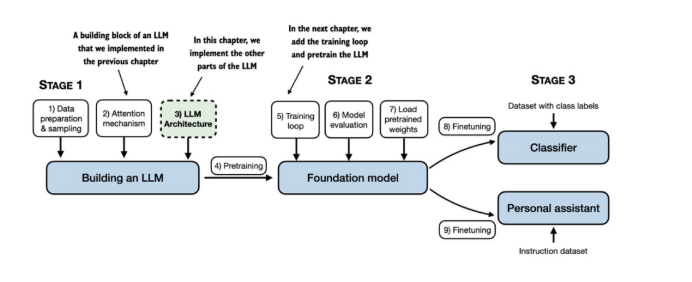

GPT là mô hình ngôn ngữ thuộc nhóm Decoder-only Transformer, sử dụng Causal Self-Attention để dự đoán token tiếp theo

In [33]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 1024, # Context length
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of attention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

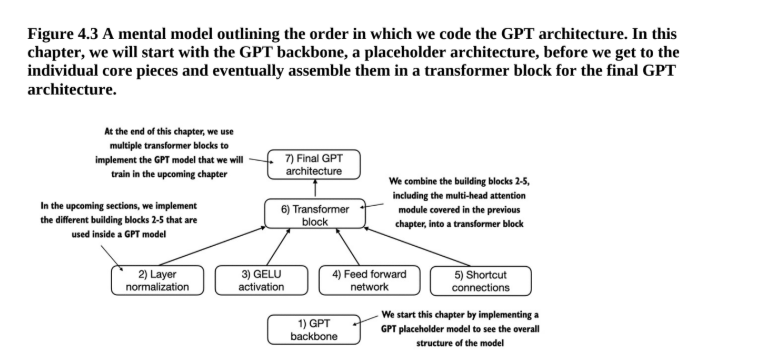

In [5]:
import torch
import torch.nn as nn


class DummyGPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        
        # Use a placeholder for TransformerBlock
        self.trf_blocks = nn.Sequential(
            *[DummyTransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        
        # Use a placeholder for LayerNorm
        self.final_norm = DummyLayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits


class DummyTransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        # A simple placeholder

    def forward(self, x):
        # This block does nothing and just returns its input.
        return x


class DummyLayerNorm(nn.Module):
    def __init__(self, normalized_shape, eps=1e-5):
        super().__init__()
        # The parameters here are just to mimic the LayerNorm interface.

    def forward(self, x):
        # This layer does nothing and just returns its input.
        return x

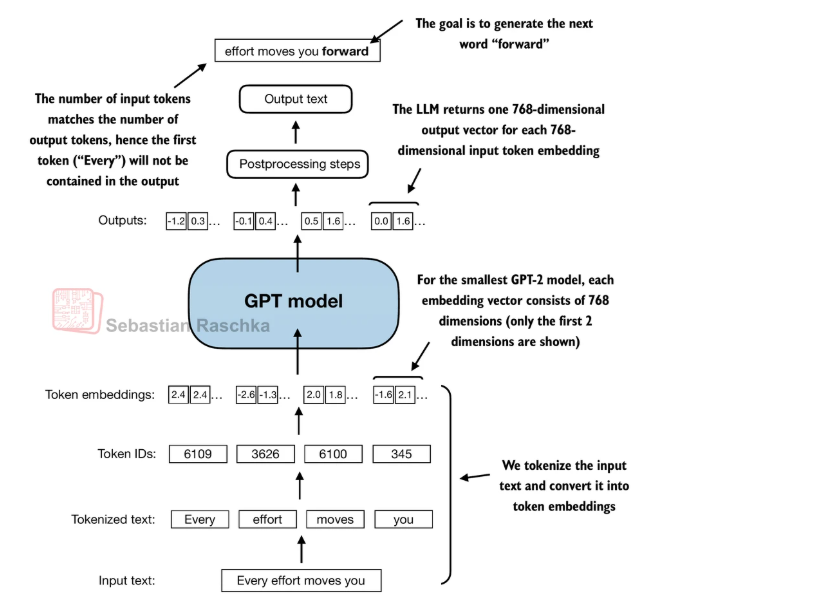

In [12]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

batch = []

txt1 = "what is your name?"
txt2 = "My name is Bin."

batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

tensor([[10919,   318,   534,  1438,    30],
        [ 3666,  1438,   318, 20828,    13]])


In [16]:
torch.manual_seed(123)
model = DummyGPTModel(GPT_CONFIG_124M)

logits = model(batch)
print("Output shape:", logits.shape)  # Should be (batch_size, seq_len, vocab_size)
print("Logits:", logits)  # Logits for each token in the batch

Output shape: torch.Size([2, 5, 50257])
Logits: tensor([[[-0.6708,  0.5141, -0.2352,  ..., -0.9224, -0.6937,  0.7023],
         [-0.1218,  0.2590, -1.2314,  ..., -0.0439, -0.3229,  0.7750],
         [ 0.0104,  0.0162, -0.0143,  ...,  2.4979,  1.3450, -0.2081],
         [-0.2888,  0.4555, -0.2284,  ...,  1.6952, -0.6183, -0.4840],
         [-0.3927, -0.2701,  0.1616,  ..., -0.4136, -0.7280, -0.0546]],

        [[-0.2644, -0.0142, -1.6014,  ...,  1.7586, -0.5959, -0.1534],
         [ 0.0116,  0.7120, -0.0328,  ...,  0.4326,  0.0533,  0.7597],
         [ 0.8612, -0.0470, -0.2792,  ..., -0.8511, -0.3645, -0.9481],
         [ 0.0658,  0.5299, -0.2424,  ...,  2.2574,  0.0414, -0.6606],
         [-0.6025,  0.3641,  0.6339,  ...,  1.1568,  0.3109,  0.3498]]],
       grad_fn=<UnsafeViewBackward0>)


## 4.2 Normalizing activations with layer normalization
- Layer normalization, also known as LayerNorm (Ba et al. 2016), centers the activations of a neural network layer around a mean of 0 and normalizes their variance to 1
- This stabilizes training and enables faster convergence to effective weights
- Layer normalization is applied both before and after the multi-head attention module within the transformer block, which we will implement later; it's also applied before the final output layer
- 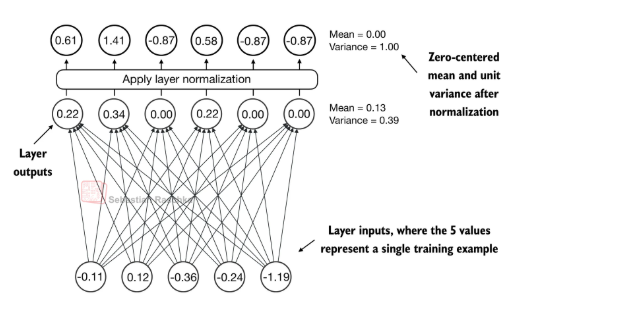

**có nghĩa là cái lớp Norm này là kỹ thuật đưa các giá trị ddafu ra của một lớp nn về một thang đo mới ổn định hơn**
```
như ở hình vẽ là đưa ra sao cho giá trị trung bình mean xấp sỉ 0 
phương sai bằng 1
Layer Normalization giúp ổn định các giá trị activation trong quá trình huấn luyện.


```
Công thức chuẩn hóa:
$$
\hat{x}=\frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}
$$

Sau đó áp dụng hai tham số học được:
$$
y=\gamma\hat{x}+\beta
$$

Trong đó:
Thành phần	Ý nghĩa

  - (\mu\)	Mean của các features
  - (\sigma^2\)	Variance của các features
  - (\epsilon\)	Số rất nhỏ để tránh chia cho 0
  - (\gamma\)	Tham số scale học được
  - (\beta\)	Tham số shift học được

- Phân biệt với BatchNorm: LayerNorm chuẩn hóa trên chiều features của từng token, không phụ thuộc vào thống kê của những mẫu khác trong batch.

In [17]:
torch.manual_seed(123)

# create 2 training examples with 5 dimensions (features) each
batch_example = torch.randn(2, 5) 

layer = nn.Sequential(nn.Linear(5, 6), nn.ReLU())
out = layer(batch_example)
print(out)

tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)


In [18]:
mean = out.mean(dim=-1, keepdim=True)
var = out.var(dim=-1, keepdim=True)

print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[0.1324],
        [0.2170]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[0.0231],
        [0.0398]], grad_fn=<VarBackward0>)


Above, we normalized the features of each input
Now, using the same idea, we can implement a LayerNorm class:

In [19]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift


Scale and shift

Note that in addition to performing the normalization by subtracting the mean and dividing by the variance, we added two trainable parameters, a scale and a shift parameter
The initial scale (multiplying by 1) and shift (adding 0) values don't have any effect; however, scale and shift are trainable parameters that the LLM automatically adjusts during training if it is determined that doing so would improve the model's performance on its training task
This allows the model to learn appropriate scaling and shifting that best suit the data it is processing
Note that we also add a smaller value (eps) before computing the square root of the variance; this is to avoid division-by-zero errors if the variance is 0
Biased variance

In the variance calculation above, setting unbiased=False means using the formula 
 
 to compute the variance where n is the sample size (here, the number of features or columns); this formula does not include Bessel's correction (which uses n-1 in the denominator), thus providing a biased estimate of the variance

For LLMs, where the embedding dimension n is very large, the difference between using n and n-1 is negligible

However, GPT-2 was trained with a biased variance in the normalization layers, which is why we also adopted this setting for compatibility reasons with the pretrained weights that we will load in later chapters

Let's now try out LayerNorm in practice:

Layer Normalization
$$
\hat{x}=\frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}
$$
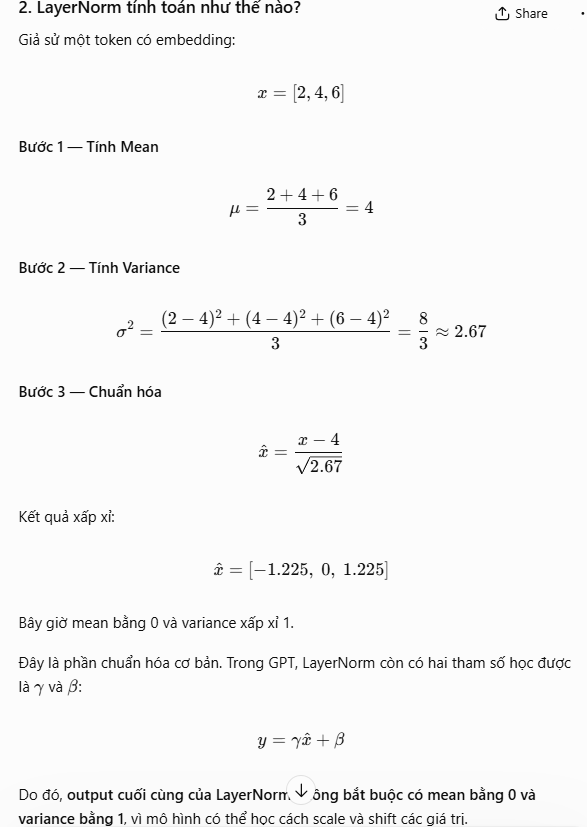  


In [20]:
ln = LayerNorm(emb_dim=6)
out_ln = ln(out)

In [21]:
mean = out_ln.mean(dim=-1, keepdim=True)
var = out_ln.var(dim=-1, unbiased=False, keepdim=True)

print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[ 1.9868e-08],
        [-1.9868e-08]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[0.9995],
        [0.9997]], grad_fn=<VarBackward0>)


LayerNorm thường được nằm ở đâu
thường là nó có được tính theo 
Công thức:
$$
\boxed{\text{Total LayerNorm}=2\times n_{\text{layers}}+1}
$$

## Active function GELU

- GELU là hàm kích hoạt phi tuyến được sử dụng trong Feed-Forward Network của GPT-2.
$$
\operatorname{GELU}(x)=x\Phi(x)
$$

Với \(\Phi(x)\) là hàm phân phối tích lũy của phân phối chuẩn.

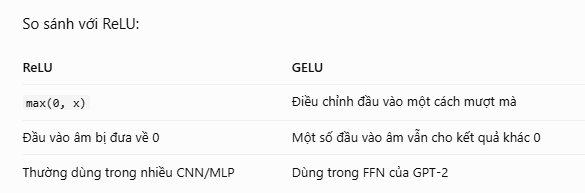

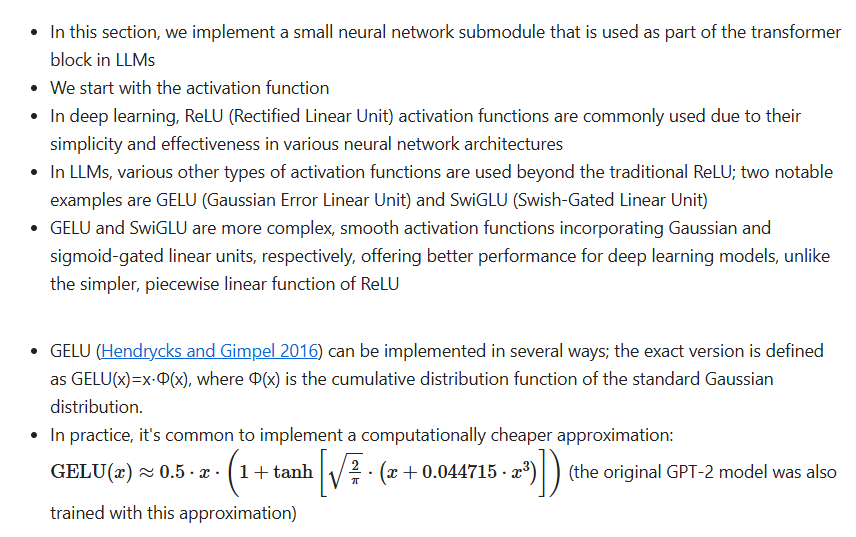

In [22]:

class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) * 
            (x + 0.044715 * torch.pow(x, 3))
        ))

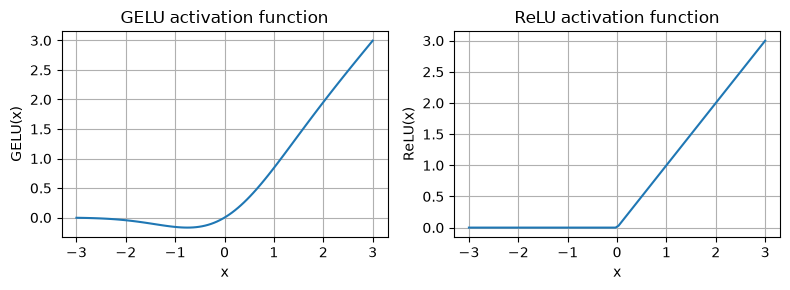

In [23]:
import matplotlib.pyplot as plt

gelu, relu = GELU(), nn.ReLU()

# Some sample data
x = torch.linspace(-3, 3, 100)
y_gelu, y_relu = gelu(x), relu(x)

plt.figure(figsize=(8, 3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)

plt.tight_layout()
plt.show()

ReLU: Chuyển toàn bộ giá trị âm thành 0.

GELU: Giảm độ lớn của tín hiệu âm một cách mượt mà, cho phép một phần tín hiệu đi qua.

Ứng dụng: ReLU phổ biến trong CNN/MLP; GELU được dùng trong Feed-Forward Network của GPT-2 và BERT

### FeedForward

In [24]:

class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]),
        )

    def forward(self, x):
        return self.layers(x)

In [25]:
print(GPT_CONFIG_124M["emb_dim"])


768


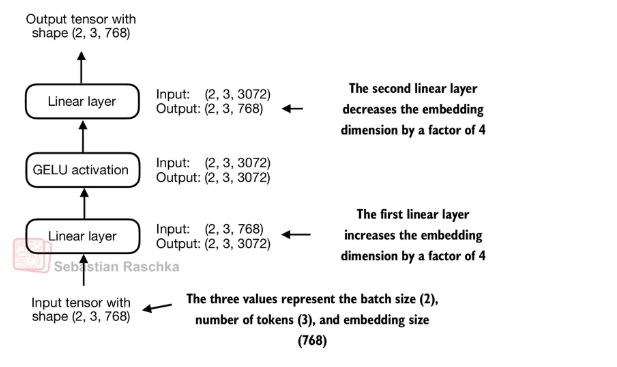

In [26]:
ffn = FeedForward(GPT_CONFIG_124M)

# input shape: [batch_size, num_token, emb_size]
x = torch.rand(2, 3, 768) 
out = ffn(x)
print(out.shape)

torch.Size([2, 3, 768])


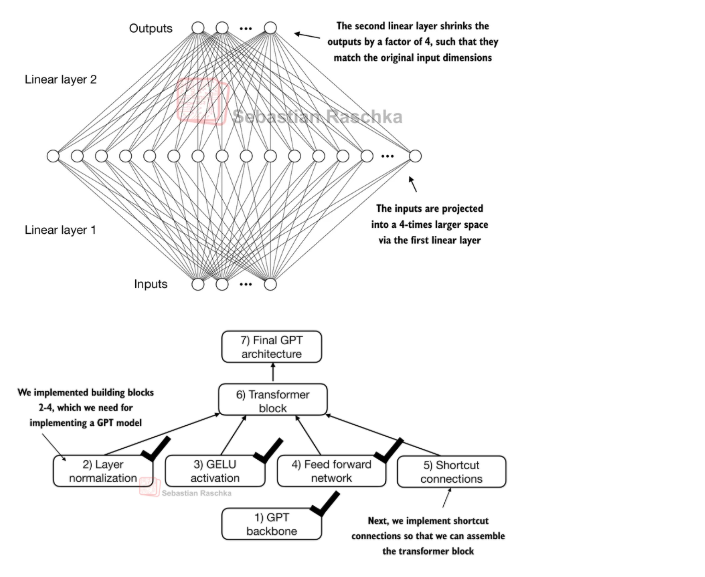

## 5. Residual Connection (Shortcut Connection)

Residual Connection là đường nối tắt đưa input cộng trực tiếp vào output của một khối xử lý.
$$
y=x+F(x)
$$

vidu

x = torch.randn(2, 6, 768)

layer = nn.Linear(768, 768)

output = x + layer(x)

Vì sao quan trọng?

Khi mô hình có nhiều lớp, gradient có thể trở nên rất nhỏ trong quá trình backpropagation (vanishing gradient). Residual Connection tạo đường truyền trực tiếp, giúp gradient đi qua mạng sâu thuận lợi hơn.

Điều kiện để cộng trực tiếp: hai tensor phải có shape tương thích.

In [27]:
class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), GELU())
        ])

    def forward(self, x):
        for layer in self.layers:
            # Compute the output of the current layer
            layer_output = layer(x)
            # Check if shortcut can be applied
            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output
            else:
                x = layer_output
        return x


def print_gradients(model, x):
    # Forward pass
    output = model(x)
    target = torch.tensor([[0.]])

    # Calculate loss based on how close the target
    # and output are
    loss = nn.MSELoss()
    loss = loss(output, target)
    
    # Backward pass to calculate the gradients
    loss.backward()

    for name, param in model.named_parameters():
        if 'weight' in name:
            # Print the mean absolute gradient of the weights
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")

In [28]:
layer_sizes = [3, 3, 3, 3, 3, 1]  

sample_input = torch.tensor([[1., 0., -1.]])

torch.manual_seed(123)
model_without_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=False
)
print_gradients(model_without_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.00020173587836325169
layers.1.0.weight has gradient mean of 0.0001201116101583466
layers.2.0.weight has gradient mean of 0.0007152041653171182
layers.3.0.weight has gradient mean of 0.001398873864673078
layers.4.0.weight has gradient mean of 0.005049646366387606


In [29]:

torch.manual_seed(123)
model_with_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=True
)
print_gradients(model_with_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.22169791162014008
layers.1.0.weight has gradient mean of 0.20694105327129364
layers.2.0.weight has gradient mean of 0.32896989583969116
layers.3.0.weight has gradient mean of 0.2665732204914093
layers.4.0.weight has gradient mean of 1.3258541822433472



As we can see based on the output above, shortcut connections prevent the gradients from vanishing in the early layers (towards layer.0)
We will use this concept of a shortcut connection next when we implement a transformer block

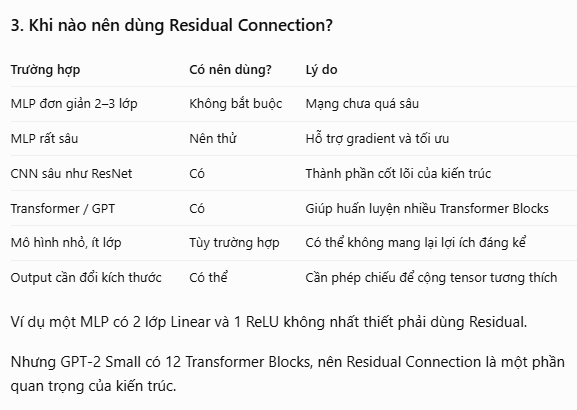

## 4.5 Connecting attention and linear layers in a transformer block

In [30]:
import torch
import torch.nn as nn

class TransformerBlock(nn.Module):
    def __init__(self, emb_dim=768, n_heads=12):
        super().__init__()

        self.norm1 = nn.LayerNorm(emb_dim)
        self.norm2 = nn.LayerNorm(emb_dim)

        self.attention = nn.MultiheadAttention(
            embed_dim=emb_dim,
            num_heads=n_heads,
            batch_first=True
        )

        self.ffn = nn.Sequential(
            nn.Linear(emb_dim, 4 * emb_dim),
            nn.GELU(),
            nn.Linear(4 * emb_dim, emb_dim)
        )

        self.dropout = nn.Dropout(0.1)

    def forward(self, x):
        # Causal mask: không nhìn token tương lai
        seq_len = x.shape[1]
        mask = torch.triu(
            torch.ones(seq_len, seq_len, device=x.device, dtype=torch.bool),
            diagonal=1
        )

        # Attention + Residual
        normalized = self.norm1(x)
        attn_output, _ = self.attention(
            normalized, normalized, normalized,
            attn_mask=mask,
            need_weights=False
        )
        x = x + self.dropout(attn_output)

        # FFN + Residual
        x = x + self.dropout(self.ffn(self.norm2(x)))

        return x


x = torch.randn(2, 10, 768)
block = TransformerBlock()

output = block(x)
print(output.shape)  # torch.Size([2, 10, 768])

torch.Size([2, 10, 768])


In [35]:
class GPTModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.tok_emb = nn.Embedding(50257, 768)
        self.pos_emb = nn.Embedding(1024, 768)
        self.drop_emb = nn.Dropout(0.1)

        self.blocks = nn.Sequential(
            *[TransformerBlock() for _ in range(12)]
        )

        self.final_norm = nn.LayerNorm(768)
        self.out_head = nn.Linear(768, 50257, bias=False)

    def forward(self, token_ids):
        B, T = token_ids.shape

        positions = torch.arange(T, device=token_ids.device)

        x = self.tok_emb(token_ids) + self.pos_emb(positions)
        x = self.drop_emb(x)
        x = self.blocks(x)
        x = self.final_norm(x)

        return self.out_head(x)

In [36]:
import torch

# 1. Khởi tạo GPT
model = GPTModel()

# 2. Tạo dữ liệu đầu vào (2 câu, mỗi câu 10 token)
token_ids = torch.randint(
    low=0,
    high=50257,
    size=(2, 10)
)

# 3. Chuyển sang chế độ inference
model.eval()

# 4. Chạy model
with torch.no_grad():
    logits = model(token_ids)

# 5. In kết quả
print("Input shape:", token_ids.shape)
print("Output shape:", logits.shape)

Input shape: torch.Size([2, 10])
Output shape: torch.Size([2, 10, 50257])


## Gen text

In [37]:
def generate_text(model, idx, max_new_tokens, context_size):
    model.eval()

    for _ in range(max_new_tokens):
        # Chỉ lấy những token cuối trong context window
        idx_cond = idx[:, -context_size:]

        with torch.no_grad():
            logits = model(idx_cond)

        # Lấy logits của vị trí cuối
        logits = logits[:, -1, :]

        # Chọn token có điểm số cao nhất
        next_token = torch.argmax(
            logits, dim=-1, keepdim=True
        )

        # Ghép token mới vào chuỗi
        idx = torch.cat((idx, next_token), dim=1)

    return idx

In [39]:
model = GPTModel()

input_ids = torch.tensor([[40, 120, 500]])

output_ids = generate_text(
    model,
    input_ids,
    max_new_tokens=5,
    context_size=1024
)

print("Token IDs:", output_ids.tolist())
print("New tokens:", output_ids[0, 3:].tolist())

Token IDs: [[40, 120, 500, 42865, 34097, 17877, 7739, 40454]]
New tokens: [42865, 34097, 17877, 7739, 40454]


In [40]:
import torch
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

# Văn bản đầu vào
text = "Hello, I am"

# Text -> Token IDs
input_ids = torch.tensor([
    tokenizer.encode(text)
])

model = GPTModel()
model.eval()

# Sinh thêm 5 token
output_ids = generate_text(
    model,
    input_ids,
    max_new_tokens=5,
    context_size=1024
)

# Token IDs -> Text
generated_text = tokenizer.decode(
    output_ids[0].tolist()
)

print("Input:", text)
print("Generated:", generated_text)

Input: Hello, I am
Generated: Hello, I am ninthllers communicationselli dominance


| API | Tác dụng |
|---|---|
| `nn.Module` | Lớp cơ sở của model |
| `__init__()` | Khai báo/khởi tạo layers và tham số |
| `forward(x)` | Quy định luồng dữ liệu; gọi qua `model(x)` |
| `nn.Sequential(...)` | Chạy các layer tuần tự |
| `nn.Embedding(V,D)` | Tra ID -> vector |
| `nn.Linear(in,out)` | Phép biến đổi affine |
| `nn.LayerNorm(D)` | Chuẩn hóa chiều đặc trưng |
| `nn.GELU()` | Activation phi tuyến |
| `nn.MultiheadAttention(...)` | Multi-head attention |
| `nn.Dropout(p)` | Dropout khi training |
| `model.eval()` | Chuyển sang chế độ evaluation |
| `torch.no_grad()` | Không xây dựng đồ thị gradient cho inference |